In [9]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import os
os.chdir("/Users/ziyaahmad/Code/mouse_vocalization_2026/jump_analysis")

df = pd.read_csv("jump_removed.csv")
print(df.columns.tolist())

rows = []
for name, g in df.groupby("file"):
    g = g.sort_values("time_s")
    f = g["frequency_raw_hz"].to_numpy() / 1000
    seg = np.cumsum(g["is_jump"].to_numpy(bool))
    for s in np.unique(seg):
        x = f[seg == s]
        rows.append({"file": name, "seg": s, "n": len(x), "level_khz": np.median(x)})

segs = pd.DataFrame(rows)
print(len(segs), segs.file.nunique())
print(segs.n.describe())

['file', 'time_s', 'frequency_hz', 'frequency_raw_hz', 'amplitude', 'is_jump']
3107 2228
count    3107.000000
mean       66.660444
std        54.915561
min         3.000000
25%        26.000000
50%        55.000000
75%        91.500000
max       361.000000
Name: n, dtype: float64


2658 2223


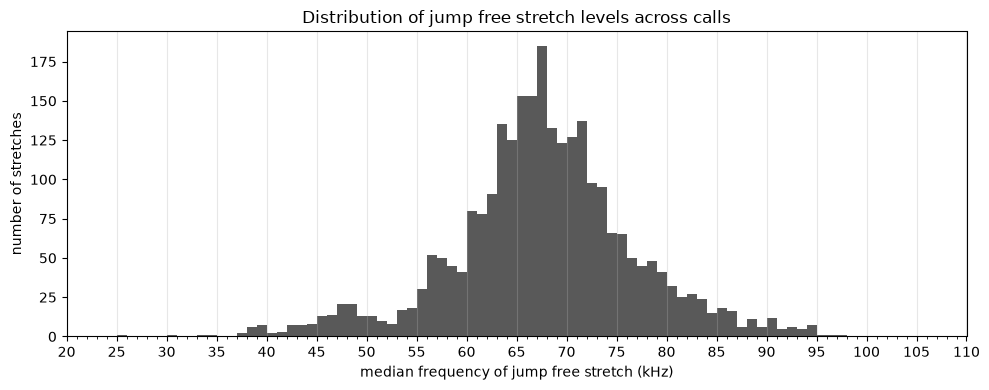

In [12]:
from matplotlib.ticker import MultipleLocator

s = segs[segs.n >= 10]
print(len(s), s.file.nunique())

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(s.level_khz, bins=np.arange(20, 110, 1), color="0.35")
ax.set_title("Distribution of jump free stretch levels across calls")
ax.set_xlabel("median frequency of jump free stretch (kHz)")
ax.set_ylabel("number of stretches")
ax.set_xlim(20, 110)
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_minor_locator(MultipleLocator(1))
ax.grid(axis="x", which="major", alpha=0.3)
fig.tight_layout()
fig.savefig("hist_segment_levels.png", dpi=200)
plt.show()

1040 605


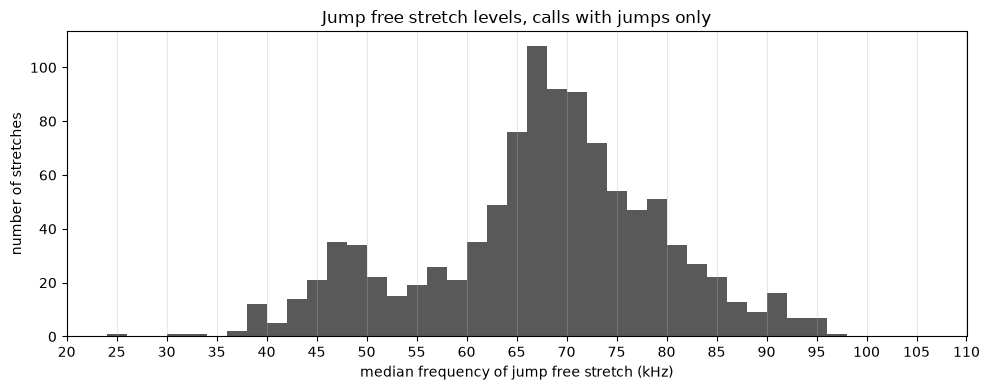

In [13]:
jc = set(df.loc[df.is_jump.astype(bool), "file"])
sj = segs[(segs.n >= 10) & (segs.file.isin(jc))]
print(len(sj), sj.file.nunique())

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(sj.level_khz, bins=np.arange(20, 110, 2), color="0.35")
ax.set_title("Jump free stretch levels, calls with jumps only")
ax.set_xlabel("median frequency of jump free stretch (kHz)")
ax.set_ylabel("number of stretches")
ax.set_xlim(20, 110)
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.grid(axis="x", which="major", alpha=0.3)
fig.tight_layout()
plt.show()

879 22.734375


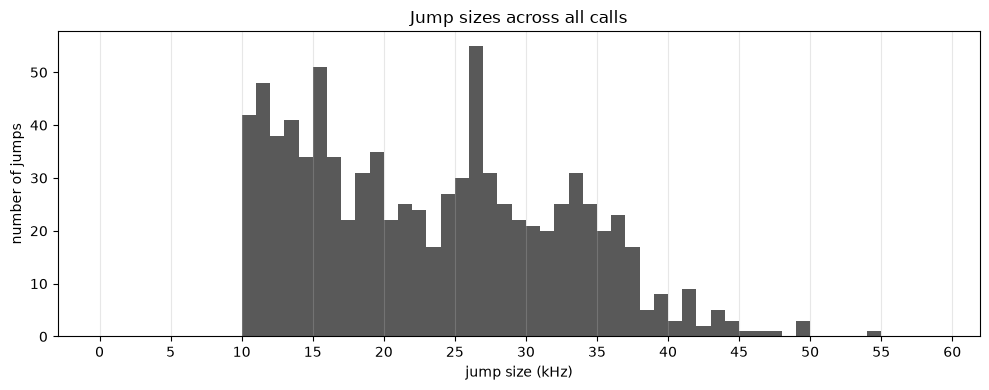

In [14]:
rows = []
for name, g in df.groupby("file"):
    g = g.sort_values("time_s")
    f = g["frequency_raw_hz"].to_numpy() / 1000
    for i in np.flatnonzero(g["is_jump"].to_numpy(bool)):
        if i > 0:
            rows.append(abs(f[i] - f[i - 1]))

sizes = np.array(rows)
print(len(sizes), np.median(sizes))

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(sizes, bins=np.arange(0, 60, 1), color="0.35")
ax.set_title("Jump sizes across all calls")
ax.set_xlabel("jump size (kHz)")
ax.set_ylabel("number of jumps")
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.grid(axis="x", which="major", alpha=0.3)
fig.tight_layout()
plt.show()